# 02 · The PSF and how its effect on the shapes is removed

**Why this matters.**  The smallest lags in the fit (0.01-0.03 ly) are only
3-10 grid pixels, and the PSF in the echo frame has a lag FWHM of ~0.018 ly.
Blurring makes structure look rounder and smoother, so without a correction
the fitted axis ratios and slope would be biased.

**Approach.**
1. Build the PSF chain from the in-flight WebbPSF model plus the detector,
   drizzle and resampling steps, and check it against stars in the mosaic.
2. Map it into the (U, V) plane with the local Jacobian.
3. Calibrate the bias of the shape fit by **injection**: synthetic 3D fields
   of known shape, sliced at the seven epoch depths, blurred by the full chain
   at each epoch's roll angle, with noise added, then fitted exactly like the
   data.  The median (fitted - true) is tabulated against the tilt of the long
   axis and subtracted from each window.

A direct forward-model fit (convolving the model S2 with the PSF inside the
fit) was also tried; on real windows it was unstable, so the injection
calibration is used.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mabsf import config as C, data as D, geometry as G, preprocess as P, psf, fitting as F, plotting
from mabsf.checks import check, targets

plotting.style()
RECOMPUTE = False      # True: rerun the injection calibration (`mabsf calibrate`, ~10 min on 8 cores)
Z = psf.psf_inputs()
print('stars in the stack:', int(Z['n_stars']))

stars in the stack: 52


## 1. The PSF on the sky, and a check against stars

The model mosaic PSF is the WebbPSF optics times the 63 mas detector pixel,
the 60 mas drizzle box and an extra Gaussian of sigma 32.5 mas.  It is
compared with the median of the isolated bright stars in the with-stars
mosaic.  The extra Gaussian stands for jitter and the drizzle kernel; its
width was chosen to match this stack.  The sensitivity analysis (notebook 06)
varies it by +-10 mas.

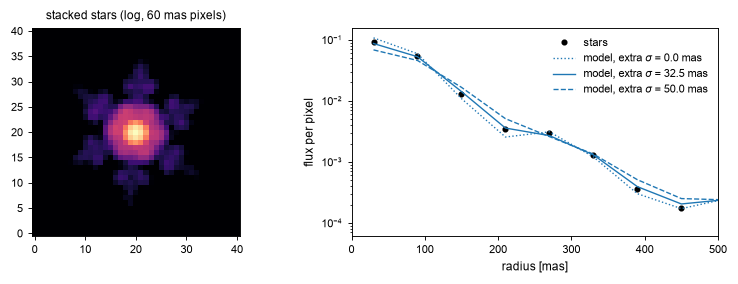

In [2]:
def model_mosaic_psf(extra_sigma, n=41, pix=0.060):
    o = psf.otf()
    q = np.fft.fftfreq(n, d=pix); QX, QY = np.meshgrid(q, q)
    T = (o(QX, QY) * np.sinc(QX * psf.DET_PX) * np.sinc(QY * psf.DET_PX) * np.sinc(QX * pix) * np.sinc(QY * pix)
         * np.exp(-2 * np.pi ** 2 * extra_sigma ** 2 * (QX ** 2 + QY ** 2)))
    img = np.real(np.fft.fftshift(np.fft.ifft2(T)))
    return img / img[np.hypot(*np.mgrid[-20:21, -20:21]) <= 12].sum()

def radial(img):
    r = np.hypot(*np.mgrid[-20:21, -20:21]); rb = np.arange(0, 13)
    return 0.5 * (rb[1:] + rb[:-1]), np.array([img[(r >= a) & (r < b)].mean() for a, b in zip(rb[:-1], rb[1:])])

fig, axs = plt.subplots(1, 2, figsize=(plotting.W_IN, 2.6))
axs[0].imshow(np.log10(np.maximum(Z['star_stack'], 1e-5)), origin='lower', cmap='magma', vmin=-4)
axs[0].set_title('stacked stars (log, 60 mas pixels)')
rr, ps = radial(Z['star_stack'])
axs[1].semilogy(rr * 60, ps, 'ko', ms=3, label='stars')
for s, ls in ((0.0, ':'), (0.0325, '-'), (0.05, '--')):
    axs[1].semilogy(rr * 60, radial(model_mosaic_psf(s))[1], ls=ls, color='C0',
                    label='model, extra $\\sigma$ = %.1f mas' % (1e3 * s))
axs[1].set_xlabel('radius [mas]'); axs[1].set_ylabel('flux per pixel'); axs[1].legend()
axs[1].set_xlim(0, 500)
fig.tight_layout()

## 2. The PSF in the echo frame

A sky frequency q relates to a UV frequency k through J, the local Jacobian
d(U, V)/d(col, row).  The structure function is quadratic in the image, so
what matters is the **power transfer** T^2(k) and its Fourier transform, the
lag kernel (the PSF's autocorrelation).  The seven roll angles differ, so the
epoch-averaged PSF is close to round on the sky; the lag kernel uses the
azimuthally averaged optics.

cloud Jacobian J [ly per mosaic pixel]:
 [[-3.66e-03 -9.00e-05]
 [-3.20e-04 -3.36e-03]]
singular values / grid step: 1.176, 1.018
lag FWHM of the PSF 0.0180 ly; after Fourier deconvolution (gain cap 20x) 0.0113 ly


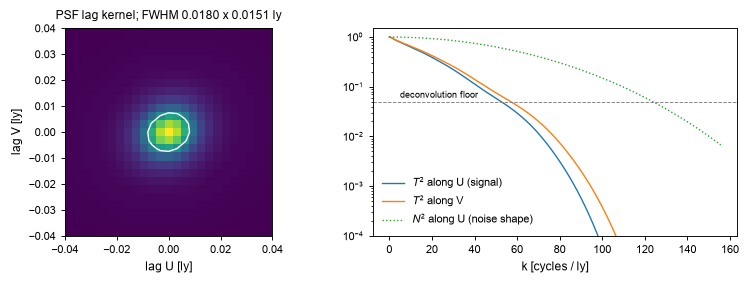

In [3]:
J = Z['J']
print('cloud Jacobian J [ly per mosaic pixel]:\n', J.round(5))
print('singular values / grid step: %.3f, %.3f' % tuple(np.linalg.svd(J, compute_uv=False) / C.PIX_LY))
g = psf.lag_psf(J)
maj, mnr, pa = psf.fwhm_axes(g)
fw_real, fw_eff = psf.effective_fwhm(J)
fig, axs = plt.subplots(1, 2, figsize=(plotting.W_IN, 2.6))
ext = np.array([-psf.KHALF, psf.KHALF, -psf.KHALF, psf.KHALF]) * C.PIX_LY
axs[0].imshow(g, origin='lower', extent=ext, cmap='viridis')
axs[0].contour(np.linspace(*ext[:2], g.shape[1]), np.linspace(*ext[2:], g.shape[0]), g, [0.5 * g.max()], colors='w')
axs[0].set_xlim(-0.04, 0.04); axs[0].set_ylim(-0.04, 0.04)
axs[0].set_xlabel('lag U [ly]'); axs[0].set_ylabel('lag V [ly]')
axs[0].set_title('PSF lag kernel; FWHM %.4f x %.4f ly' % (maj, mnr))
k1 = np.fft.fftshift(np.fft.fftfreq(512, d=C.PIX_LY))
T2, N2 = psf.transfer(*np.meshgrid(k1, k1), J, *psf.symmetric_sky_mtf())
axs[1].semilogy(k1[256:], T2[256, 256:], label='$T^2$ along U (signal)')
axs[1].semilogy(k1[256:], T2[256:, 256], label='$T^2$ along V')
axs[1].semilogy(k1[256:], N2[256, 256:], ':', label='$N^2$ along U (noise shape)')
axs[1].axhline(psf.T2MIN, color='0.5', lw=0.6, ls='--'); axs[1].text(5, psf.T2MIN * 1.2, 'deconvolution floor', fontsize=6)
axs[1].set_ylim(1e-4, 1.5); axs[1].set_xlabel('k [cycles / ly]'); axs[1].legend()
fig.tight_layout()
print('lag FWHM of the PSF %.4f ly; after Fourier deconvolution (gain cap 20x) %.4f ly' % (fw_real, fw_eff))

## 3. Injection: what the PSF does to a field of known shape

The injected fields are Gaussian random fields with
S2 = A |L^{-1} d|^0.8, i.e. the model the data are fitted with.  Two shapes
are used (a2/a1, a3/a2 = 0.28, 0.50 and 0.50, 0.40), at long-axis tilts of
0-90 deg from W; 3 random seeds per tilt, 9 at tilts >= 60 deg (where most
windows lie): **78 fields**.  Each uses the lag geometry, depths, Jacobian and
per-epoch noise of a real 0.64 ly template window, and the real roll angle of
each epoch.

template noise rms per epoch: [0.014  0.015  0.0146 0.0137 0.0152 0.0224 0.0258]


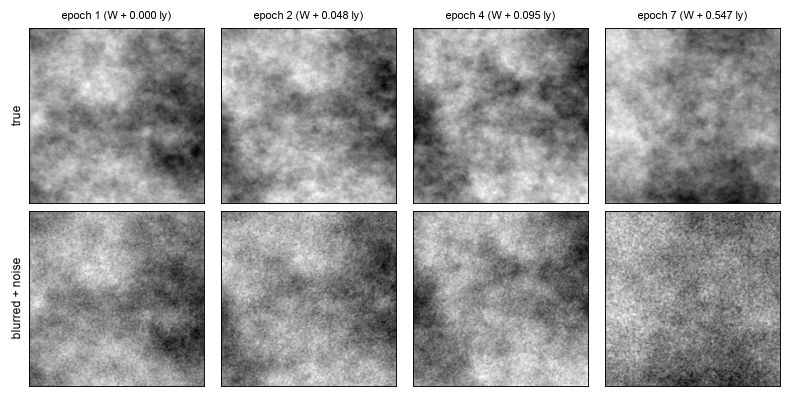

In [4]:
geo, Jt, sig_noise = psf.calibration_template()
w_vals = geo[200]['W_values']
sl = psf.make_field(psf.SHAPES['a2a1=0.28,a3a2=0.50'], (60, 41, 97), psf.FIELD_ALPHA, 11, w_vals)
bl = psf.blur(sl * 0.05, Jt, 1011, sig_noise) / 0.05
fig, axs = plt.subplots(2, 4, figsize=(plotting.W_IN, 3.6))
for j, e in enumerate((0, 1, 3, 6)):
    axs[0, j].imshow(sl[e, 60:260, 60:260], origin='lower', cmap='gray')
    axs[1, j].imshow(bl[e, 60:260, 60:260], origin='lower', cmap='gray')
    axs[0, j].set_title('epoch %d (W + %.3f ly)' % (e + 1, w_vals[e] - w_vals[0]), fontsize=7)
for a in axs.flat:
    a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel('true'); axs[1, 0].set_ylabel('blurred + noise')
fig.tight_layout()
print('template noise rms per epoch:', np.round(sig_noise, 4))

The fitted shapes of the true and the observed slices give the bias of each
field.  The calibration over all 78 fields is cached in
`results/psf_calibration.csv` (it also holds the variants used in the
sensitivity analysis).

78 fields


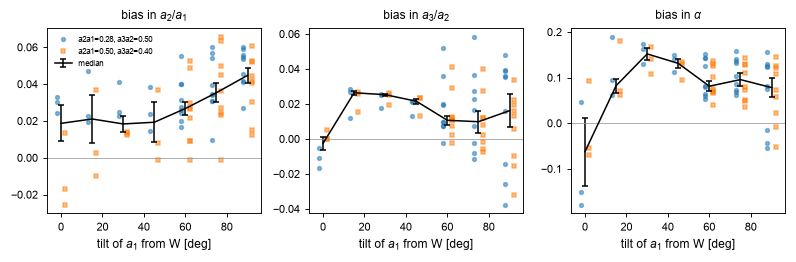

,a2a1,a3a2,a3a1,b2b1,alpha
tilt,,,,,
0,0.0187,-0.0026,0.0072,-0.0026,-0.0623
15,0.0211,0.0264,0.0168,0.0242,0.0823
30,0.0184,0.0253,0.0185,0.0240,0.1521
45,0.0193,0.0216,0.0144,0.0220,0.1313
60,0.0268,0.0107,0.0185,0.0211,0.0812
75,0.0354,0.0098,0.0246,0.0257,0.0957
90,0.0448,0.0162,0.0278,0.0319,0.0782


In [5]:
if RECOMPUTE or not os.path.exists(psf.calibration_path()):
    psf.run_calibration('all', procs=8)
cal = psf.calibration_table('dedup')
print(len(cal) // 2, 'fields')
med, sem = psf.bias_by_tilt(cal)
fig, axs = plt.subplots(1, 3, figsize=(plotting.W_IN, 2.4), sharex=True)
d = cal[cal.fit == 'observed'].set_index(['shape', 'tilt', 'seed'])[list(psf.CORRECTED)] - \
    cal[cal.fit == 'clean'].set_index(['shape', 'tilt', 'seed'])[list(psf.CORRECTED)]
d = d.reset_index()
for a, q, lab in zip(axs, ('a2a1', 'a3a2', 'alpha'), ('$a_2/a_1$', '$a_3/a_2$', r'$\alpha$')):
    for sh, mk in zip(psf.SHAPES, 'os'):
        x = d[d['shape'] == sh]
        a.plot(x.tilt + (2 if mk == 's' else -2), x[q], mk, ms=2.5, alpha=0.5, label=sh.replace(',', ', '))
    a.errorbar(med.index, med[q], sem[q], color='k', lw=1, capsize=2, label='median')
    a.axhline(0, color='0.6', lw=0.5)
    a.set_title('bias in ' + lab); a.set_xlabel('tilt of $a_1$ from W [deg]')
axs[0].legend(fontsize=5.5)
fig.tight_layout()
med.round(4)

The PSF **raises** a2/a1 and a3/a2 (blurred structures look rounder) and
**steepens** alpha (it removes small-scale power).  The bias depends on the
tilt, because the tilt sets how much of each axis lies in the blurred plane.

## 4. Correcting the windows

For each window, the median bias at its own measured inclination
(interpolated between the injected tilts) is subtracted from a2/a1, a3/a2,
a3/a1, b2/b1 and alpha.  Two safeguards:
- a correction may at most halve a ratio (the calibration covers ratios of
  0.26-0.50; smaller values would be extrapolation);
- collapsed fits (a ratio < 0.02) are left unchanged.

The error bars are not inflated: the field-to-field scatter of the bias is
mostly noise, which the jackknife of each real window already includes.

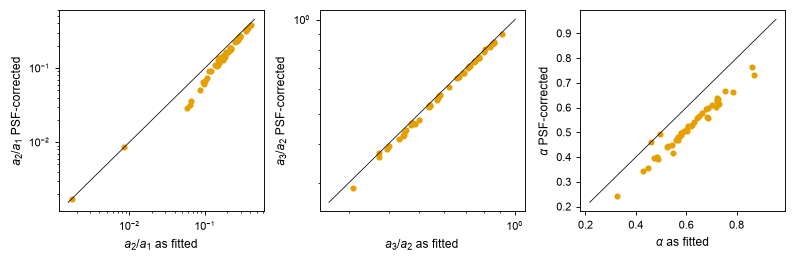

,median as fitted,median corrected
a2a1,0.185,0.149
a3a2,0.581,0.571
alpha,0.602,0.509


In [6]:
wins = P.sample_windows()
raw = F.table(wins)
cor = psf.correct(raw)
fig, axs = plt.subplots(1, 3, figsize=(plotting.W_IN, 2.4))
for a, q, lab, lg in zip(axs, ('a2a1', 'a3a2', 'alpha'), ('$a_2/a_1$', '$a_3/a_2$', r'$\alpha$'), (True, True, False)):
    a.plot(raw[q], cor[q], 'o', ms=3, color=plotting.C_WIN)
    lim = [min(raw[q].min(), cor[q].min()) * 0.9, max(raw[q].max(), cor[q].max()) * 1.1]
    a.plot(lim, lim, 'k-', lw=0.5)
    if lg:
        a.set_xscale('log'); a.set_yscale('log')
        a.xaxis.set_minor_formatter(plt.NullFormatter()); a.yaxis.set_minor_formatter(plt.NullFormatter())
    a.set_xlabel(lab + ' as fitted'); a.set_ylabel(lab + ' PSF-corrected')
fig.tight_layout()
pd.DataFrame({'median as fitted': raw[['a2a1', 'a3a2', 'alpha']].median(),
              'median corrected': cor[['a2a1', 'a3a2', 'alpha']].median()}).round(3)

## 5. Checks

* the PSF inputs (model, star stack, Jacobian) are identical to the original;
* the bias table of the paper's first calibration ('published', in which some
  synthetic fields were included more than once) is reproduced exactly from
  its stored per-field table;
* corrected window values match the original pipeline for both calibrations.

The original pipeline used the stationary S2 estimator, so these checks fit
and correct with `C.FIRST_SUBMISSION` (the analysis above uses the exact
estimator, the default).  Its calibration ('stationary' variant) is bit-identical
to the original calibration of that estimator.

In [7]:
import hashlib
sha = lambda a: hashlib.sha1(np.ascontiguousarray(a).tobytes()).hexdigest()[:16]
TP = targets()['psf']
for k_ in ('psf_os', 'star_stack'):
    check('PSF input %s (sha1 match)' % k_, int(sha(Z[k_]) == TP['psf_inputs'][k_]), 1, rtol=0)
check('cloud Jacobian J', Z['J'], TP['psf_inputs']['J'], rtol=1e-12)
check('number of stars stacked', Z['n_stars'], TP['psf_inputs']['n_stars'], rtol=0)
medp, _ = psf.bias_by_tilt(psf.calibration_table('published'))
for q in psf.CORRECTED:
    check('published bias(tilt) %s' % q, medp[q].values, TP['bias_by_tilt'][q], rtol=0, atol=6e-7)   # stored to 6 decimals
W = pd.read_csv('../validation/targets_windows.csv')
raw_fs = F.table(wins, C.FIRST_SUBMISSION)
for calib, suf in (('dedup', 'dedup'), ('published', 'base')):
    c = psf.correct(raw_fs, calib, variant='stationary').merge(W, on=['row', 'col'])
    for q in ('a2a1', 'a3a2', 'alpha'):
        check('corrected %s, %s calibration' % (q, calib), c[q].values, c['%s_%s' % (q, suf)].values,
              rtol=1e-4 if calib == 'dedup' else 1e-9)

ok   PSF input psf_os (sha1 match)                    1  (expected 1)
ok   PSF input star_stack (sha1 match)                1  (expected 1)
ok   cloud Jacobian J                                 [[-3.66021e-03 -8.73791e-05]
 [-3.19169e-04 -3.35648e-03]]  (expected [[-3.66021e-03 -8.73791e-05]
 [-3.19169e-04 -3.35648e-03]])
ok   number of stars stacked                          52  (expected 52)
ok   published bias(tilt) a2a1                        [0.01294 0.01141 0.01991 0.01233 0.02028 0.03281 0.05482]  (expected [0.01294 0.01141 0.01991 0.01233 0.02028 0.03281 0.05482])
ok   published bias(tilt) a3a2                        [0.00747 0.03521 0.02873 0.0211  0.01934 0.01499 0.01598]  (expected [0.00747 0.03521 0.02873 0.0211  0.01934 0.01499 0.01598])
ok   published bias(tilt) a3a1                        [0.00856 0.01181 0.01732 0.01255 0.01497 0.02467 0.03318]  (expected [0.00856 0.01181 0.01732 0.01255 0.01497 0.02467 0.03318])
ok   published bias(tilt) b2b1                        [0.0